In [1]:
import os
import sys
import eval_utils
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import tensorflow as tf
from tensorflow import keras

from sklearn.preprocessing import MinMaxScaler

import matplotlib.pyplot as plt
from matplotlib import gridspec
import json
import random
import warnings
from preProcessingData          import PreProcessData


os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # or any {'0', '1', '2'}
os.environ.pop('TF_CONFIG', None)
os.environ.pop('CUDA_VISIBLE_DEVICES', None)
os.environ['TF_MIN_GPU_MULTIPROCESSOR_COUNT'] = '6'     
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
warnings.filterwarnings('ignore') 

print(tf.config.list_physical_devices('GPU'))

# tf.debugging.set_log_device_placement(True)
# from tensorflow.python.client import device_lib
# print(device_lib.list_local_devices())




2024-10-18 00:10:59.374702: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-10-18 00:10:59.518990: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-18 00:11:00.067570: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/ducan/anaconda3/envs/tensorflow2.10.0/lib/:/home/ducan/anaconda3/envs/tensorflow2.10.0New/lib/
2024-10-18 00:11:00.067650: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dyn

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2024-10-18 00:11:01.325276: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-10-18 00:11:01.333994: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero


In [2]:
with open('model/modelConfig.json', 'r') as configFile:
        config = json.load(configFile)
kanConfig = config["kan"]  

# ---------------------------------    
# Reactor, Separator,Stripper
# ---------------------------------
component  = kanConfig["component"]
modelName  = "kan"

seqLength = 256

np.random.seed(1)
random.seed(1)
# ---------------------------------
# Pre processing data
# ---------------------------------
preData                         = PreProcessData()
rawData                         = preData.loadCriticalData()                                            # Load the data from critical file
addedVariablesData              = preData.addition_var(rawData)                                         # Add some additional efficiency variable
cleanedData                     = preData.cleanData(rawData)
normalizedAllData               = preData.normalizeBuilinFunction(cleanedData)                          # Normalize the all data
# normalizedHealthy,healthyPos    = preData.getHealthyState(normalizedAllData)                          # Load the healthy state
effTrajectories                 = preData.getTrajectory(normalizedAllData, getValueOnly= True, headline= preData.efficiency_cr1 )         # Extract the trajectory
maniTrajectories                = preData.getTrajectory(normalizedAllData, getValueOnly= True, headline= preData.manipulated_cr1)         # Extract the trajectory


# ---------------------------------
# Create the cycles
# ---------------------------------
hours                           = preData.addFloatTime(rawData)
cycleTrajectories               = preData.getTrajectory(hours)         # Extract the trajectory

# print("----------------------------")
# print(effTrajectories)

trainEff, trainMani,trainCycle, \
valEffData, valManiData, valCycleData = preData.splitTrainValTraject(effTrajectories, maniTrajectories,cycleTrajectories)

print(len(trainEff), len(trainMani), len(trainCycle), len(valEffData), len(valManiData), len(valCycleData))
# ---------------------------
# All data
# --------------------------
trainEffNow     = trainEff + valEffData
trainManiNow    = trainMani + valManiData
trainCycleNow   = trainCycle + valCycleData
removedIdx      = []
# for idx,value in enumerate(trainEffNow):
#         if value.shape[0] <= seqLength:
#                 removedIdx.append(idx)

# trainEffNow = [item for i, item in enumerate(trainEffNow.copy()) if i not in removedIdx]
# trainManiNow = [item for i, item in enumerate(trainManiNow.copy()) if i not in removedIdx]
# trainCycleNow = [item for i, item in enumerate(trainCycleNow.copy()) if i not in removedIdx]

# for idx,value in enumerate(trainEffNow):
#         print(value.shape)


trainSeqEffData,_     = preData.splitAllDataIntoSequences(trainEffNow, seqLength= seqLength, overlap=seqLength-1)
trainSeqManiData,_    = preData.splitAllDataIntoSequences(trainManiNow, seqLength= seqLength, overlap=seqLength-1)
trainSeqCycleData,_   = preData.splitAllDataIntoSequences(trainCycleNow, seqLength= seqLength, overlap=seqLength-1)
trainSeqCycleData     = np.mean(trainSeqCycleData, axis=1)

valSeqEffData,_     = preData.splitAllDataIntoSequences(valEffData,seqLength= seqLength, overlap=seqLength-1)
valSeqManiData,_    = preData.splitAllDataIntoSequences(valManiData,seqLength= seqLength, overlap=seqLength-1)
valSeqCycleData,_   = preData.splitAllDataIntoSequences(valCycleData, seqLength= seqLength, overlap=seqLength-1)
valSeqCycleData     = np.mean(valSeqCycleData, axis=1)

print(f"The size of the train data: {trainSeqEffData.shape} {trainSeqManiData.shape} {trainSeqCycleData.shape}")
print(f"The size of the test data: {valSeqEffData.shape} {valSeqManiData.shape} {valSeqCycleData.shape}")
print(type(trainSeqCycleData))

XDIM = trainSeqEffData.shape[2]
WDIM = trainSeqManiData.shape[2]
# ---------------------------
# Single sample
# ---------------------------
# singleTraject   = trajectory["Lubricación  deficiente"][0][preData.beauEfficiencyCr1 + preData.addEfficiencyCr1]
# seqData,_       = preData.splitAndPadSequencesTensor([singleTraject,singleTraject],seqLength=kanConfig['seqLength'], overlap= kanConfig['overlap'])

# trajectory.keys()

Process:101066||2024-10-18 00:11:01,346-INFO [preProcessingData.py:loadCriticalData():255]:Loading critical MOF data from files ...
Process:101066||2024-10-18 00:11:01,731-INFO [preProcessingData.py:loadCriticalData():261]:Finish loading data from files ...
Process:101066||2024-10-18 00:11:05,727-INFO [preProcessingData.py:splitAllDataIntoSequences():807]:Spliting data into sequences now ...


9 9 9 6 6 6


Process:101066||2024-10-18 00:11:10,391-INFO [preProcessingData.py:splitAllDataIntoSequences():807]:Spliting data into sequences now ...
Process:101066||2024-10-18 00:11:14,417-INFO [preProcessingData.py:splitAllDataIntoSequences():807]:Spliting data into sequences now ...
Process:101066||2024-10-18 00:11:23,966-INFO [preProcessingData.py:splitAllDataIntoSequences():807]:Spliting data into sequences now ...
Process:101066||2024-10-18 00:11:25,978-INFO [preProcessingData.py:splitAllDataIntoSequences():807]:Spliting data into sequences now ...
Process:101066||2024-10-18 00:11:28,011-INFO [preProcessingData.py:splitAllDataIntoSequences():807]:Spliting data into sequences now ...


The size of the train data: (78506, 256, 14) (78506, 256, 10) (78506,)
The size of the test data: (34888, 256, 14) (34888, 256, 10) (34888,)
<class 'numpy.ndarray'>


In [3]:
class C_constraint(tf.keras.layers.Layer):   # Inheritance class        
    def call(self, inputdata):
        x, t = inputdata
        print("--------------------------====================")
        print(x, t)

        x_mu = tf.reduce_mean(x)
        t_mu = tf.reduce_mean(t)
        cov = tf.reduce_sum((x-x_mu)*(t-t_mu))
        print("cod",cov)
        std = tf.math.pow(tf.reduce_sum((x-x_mu)**2),0.5) * tf.math.pow(tf.reduce_sum((t-t_mu)**2),0.5)
        loss = cov/std
        loss = tf.reduce_mean(loss)
        
        self.add_loss(1*loss)
        self.add_metric(loss, aggregation='mean', name='l1')
        return x

    
class NG_constraint(tf.keras.layers.Layer):   # Inheritance class
    def __init__(self,alpha,**kwargs):  
        super().__init__(**kwargs)
        self.alpha = alpha
        
    def call(self, inputdata):
        x,t = inputdata
        x_diff = x[1:]-x[:-1]
        t_diff = t[1:]-t[:-1]
        grad = x_diff/t_diff
        loss = tf.reduce_sum(tf.math.maximum(tf.constant(0.0),grad))
        self.add_loss(self.alpha*loss)
        self.add_metric(loss, aggregation='mean', name='Grad')

        return x
    
class F_constraint(tf.keras.layers.Layer):   # Inheritance class
    def __init__(self,alpha,**kwargs):  
        super().__init__(**kwargs)
        self.alpha = alpha
        
        self.A = 0.012
        self.B = 4.95
        self.C = 0.89
        self.BETA = 6.7
        self.P = 0.5
        
    def call(self, inputdata):
        x, t = inputdata
        HI = self.C - ((t * (-np.log(1 - self.P))**(-1/self.BETA))*self.A)**self.B
        mask = tf.math.less(HI,0)
        HI = tf.where(mask,0.0,HI)
        loss = tf.reduce_mean(tf.abs(x-HI))
        
        self.add_loss(self.alpha*loss)
        self.add_metric(loss, aggregation='mean', name='l1')
        return x
    
def H_index_Proposal_CNN(latent_dims,Window_size = 100,z_size=1,cnn_dim = 85,stride = 1,alpha = 1,constraint = 'C'):
    
    x_dim = XDIM
    w_dim = WDIM
    
    inpX    = tf.keras.layers.Input(shape=(Window_size,x_dim),name = 'InpX')
    inputT  = tf.keras.layers.Input(shape=(1,),name = 'inpT')
    inpW    = tf.keras.layers.Input(shape=(Window_size,w_dim),name = 'inpW')
    
    print("-------------------------------------")
    print(inpX.shape, inputT.shape, inpW.shape)
    

    x       = inpX
    w_in    = inpW
    
    for i in latent_dims:
        x=tf.keras.layers.Conv1D(i,cnn_dim,stride,activation='relu',padding = 'same')(x)

    x = tf.keras.layers.Flatten(name = 'flatten')(x)
    x = tf.keras.layers.Dense(z_size,name="Z")(x) #activity_regularizer=regularizers.l1(10e-5)
    
    if constraint == 'C':
        # x = C_constraint(alpha, name='constrained')([x, inputT])
        x = C_constraint()([x, inputT])

    elif constraint == 'NG':
        x = tf.keras.layers.Lambda(lambda x: tf.math.l2_normalize(x), name='Z_after')(x)
        x = NG_constraint(alpha, name='constrained')([x, inputT])
    elif constraint == 'F':
        x = F_constraint(alpha, name='constrained')([x, inputT])
    else:
        raise ValueError("Invalid constraint type. Must be 'C', 'NG', or 'F'") 
    
    x = tf.keras.layers.RepeatVector(Window_size,name='repeat')(x)
    
    x = tf.keras.layers.Concatenate(axis  =-1)([x,w_in])
    for i in reversed(latent_dims):
        x = tf.keras.layers.Conv1D(i,cnn_dim,strides=1,activation='relu',padding = 'same')(x)
    x=tf.keras.layers.Dense(x_dim,name='X')(x)   
       
    model = tf.keras.models.Model([inpX,inputT,inpW],x)
    return model

In [4]:
constraint  = 'C'
# layers      =  [128,64,32,16]
layers      =  [256,128,64,32]
Window_size = seqLength
model       = H_index_Proposal_CNN(layers,Window_size,constraint = constraint)

-------------------------------------
(None, 256, 14) (None, 1) (None, 256, 10)


2024-10-18 00:11:31.830353: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-10-18 00:11:31.831233: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-10-18 00:11:31.831584: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-10-18 00:11:32.937486: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zer

--------------------------====================
Tensor("Placeholder:0", shape=(None, 1), dtype=float32) Tensor("Placeholder_1:0", shape=(None, 1), dtype=float32)
cod Tensor("c_constraint/Sum:0", shape=(), dtype=float32)


In [ ]:
OPTIMIZER   = tf.keras.optimizers.Adam(learning_rate=0.001)
LOSS        = tf.keras.losses.MeanAbsoluteError()
model.compile(optimizer=OPTIMIZER, loss=LOSS, metrics=['mae'])
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

train_ds = tf.data.Dataset.from_tensor_slices(((trainSeqEffData, trainSeqCycleData, trainSeqManiData), trainSeqEffData))
train_ds = train_ds.batch(32).shuffle(buffer_size=trainSeqEffData.shape[0])
# train_ds = train_ds.batch(32)
# Define the ModelCheckpoint callback
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
                                                        filepath='best_model.h5',  # Filepath to save the model
                                                        monitor='loss',        # Monitor validation loss (or any other metric)
                                                        save_best_only=True,       # Save only the best model
                                                        mode='min',                # 'min' because we want the lowest validation loss
                                                        verbose=1
)

history = model.fit(train_ds, epochs=20, verbose=1, callbacks=[checkpoint_callback])

plt.plot(history.history["loss"])
# plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train"],loc ="upper left")

Num GPUs Available:  1


2024-10-18 00:11:33.932509: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 2250924032 exceeds 10% of free system memory.


In [6]:
# print("Saving the model ...............")
# model.save('ckpt/VAEConstrains/my_model_128.h5')  # Save as an HDF5 file

# model       = keras.models.load_model('ckpt/VAEConstrains/my_model.h5', custom_objects={'C_constraint': C_constraint})
model       = keras.models.load_model('best_model.h5', custom_objects={'C_constraint': C_constraint})

# Show the model architecture
model.summary()
print("load model successfully")

--------------------------====================
Tensor("Placeholder:0", shape=(None, 1), dtype=float32) Tensor("Placeholder_1:0", shape=(None, 1), dtype=float32)
cod Tensor("c_constraint/Sum:0", shape=(), dtype=float32)
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 InpX (InputLayer)              [(None, 256, 14)]    0           []                               
                                                                                                  
 conv1d (Conv1D)                (None, 256, 256)     304896      ['InpX[0][0]']                   
                                                                                                  
 conv1d_1 (Conv1D)              (None, 256, 128)     2785408     ['conv1d[0][0]']                 
                                                                         

Process:98868||2024-10-18 00:03:16,248-INFO [preProcessingData.py:splitAllDataIntoSequences():807]:Spliting data into sequences now ...


(5035, 14)
150/150 [==============================] - 1s 7ms/step


Process:98868||2024-10-18 00:03:17,932-INFO [preProcessingData.py:splitAllDataIntoSequences():807]:Spliting data into sequences now ...


(613, 14)
12/12 [==============================] - 0s 9ms/step


Process:98868||2024-10-18 00:03:18,120-INFO [preProcessingData.py:splitAllDataIntoSequences():807]:Spliting data into sequences now ...


(5821, 14)
174/174 [==============================] - 1s 7ms/step


... (14 outputs left out)

Process:98868||2024-10-18 00:03:37,947-INFO [preProcessingData.py:splitAllDataIntoSequences():807]:Spliting data into sequences now ...


(10285, 14)
314/314 [==============================] - 2s 7ms/step


Process:98868||2024-10-18 00:03:41,177-INFO [preProcessingData.py:splitAllDataIntoSequences():807]:Spliting data into sequences now ...


(6403, 14)
193/193 [==============================] - 1s 7ms/step


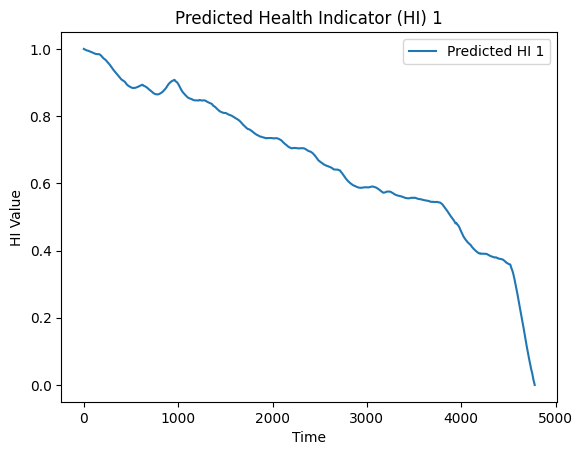

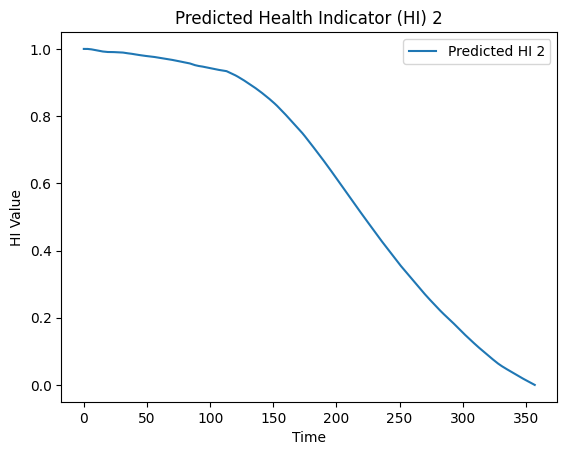

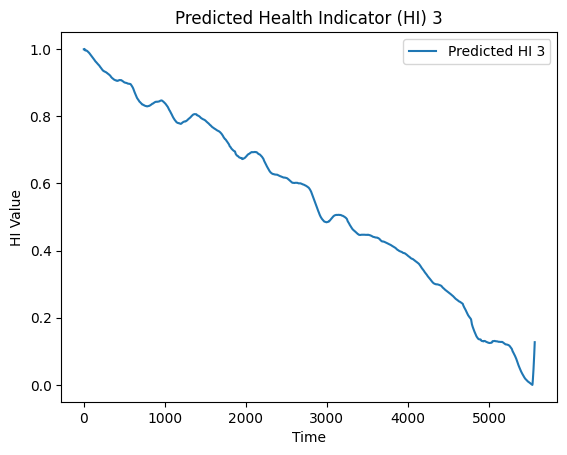

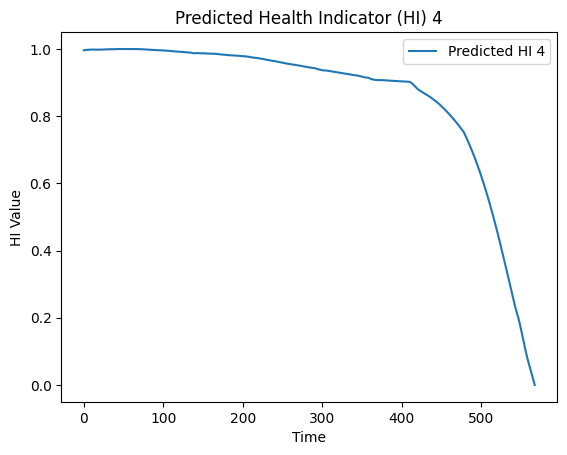

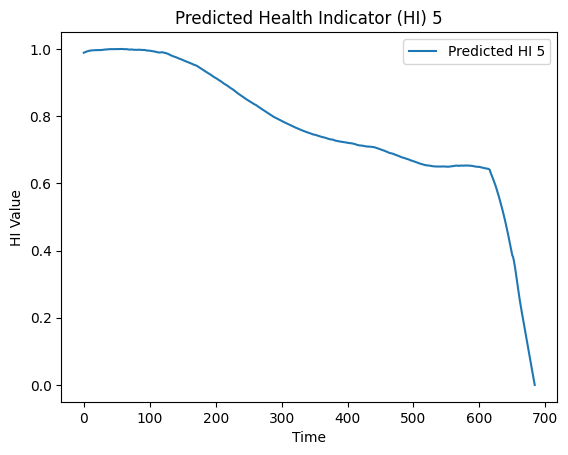

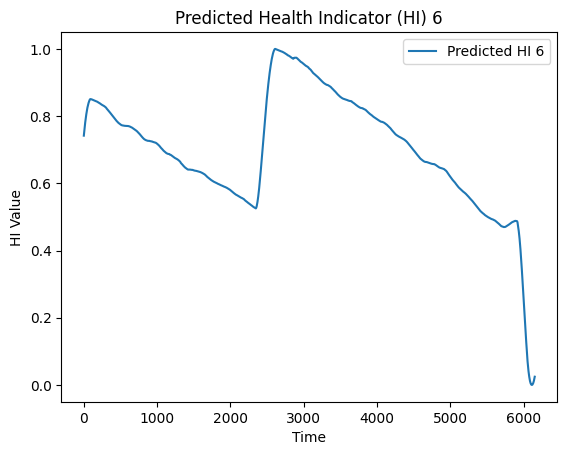

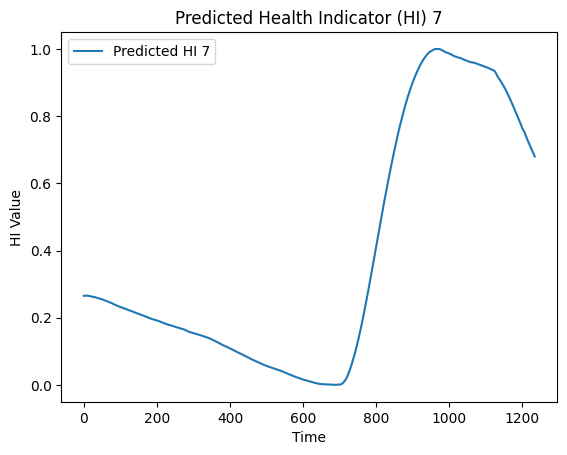

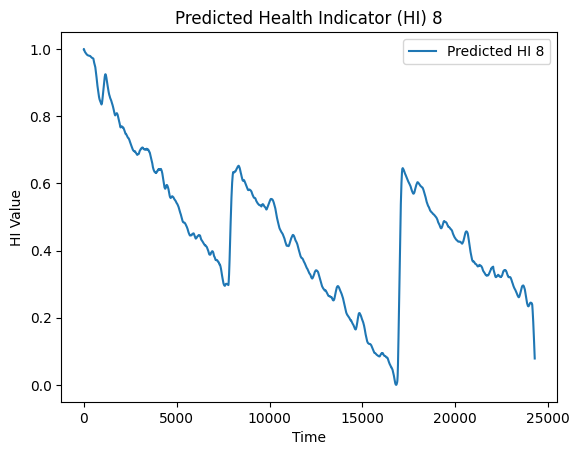

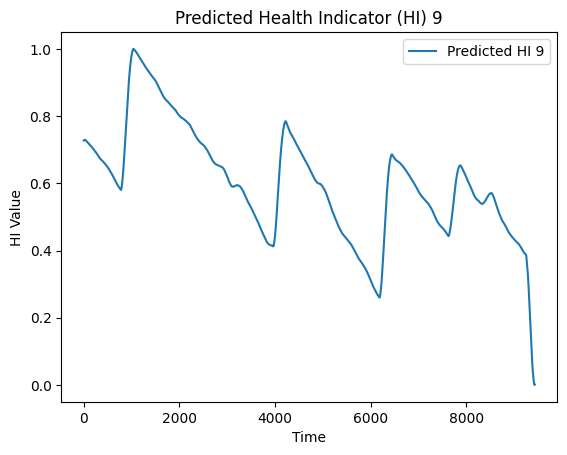

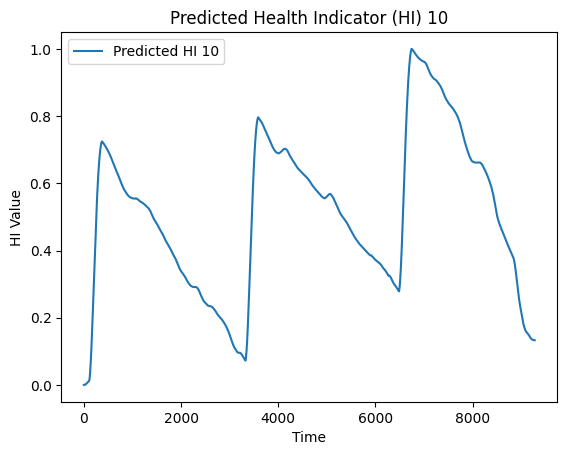

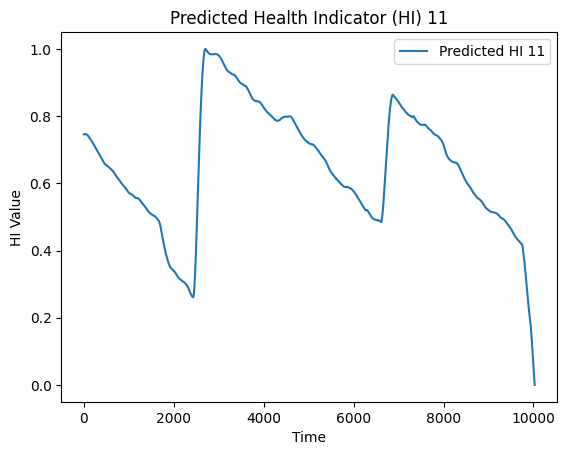

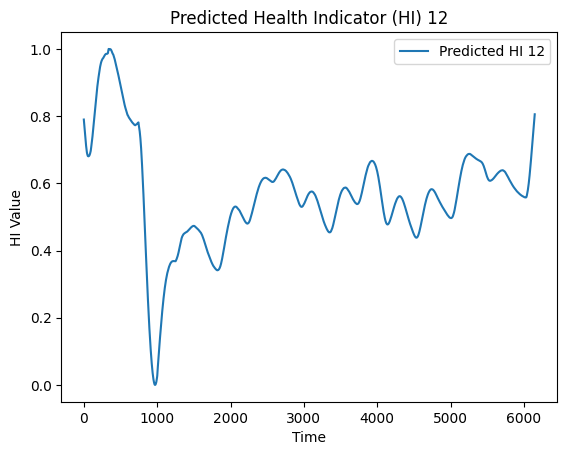

In [10]:
zAll= []
laten_extract = tf.keras.models.Model(inputs=[model.inputs[0]],
                                                outputs=[model.get_layer("Z").output])
for idx,value in enumerate(trainEffNow):
    print(value.shape)
    if value.shape[0] <seqLength:
        continue
    trainSeqEffData,_     = preData.splitAllDataIntoSequences([value],seqLength= seqLength, overlap=seqLength-1)
    # trainSeqManiData,_    = preData.splitAllDataIntoSequences([valManiData[idx]])
    # trainSeqCycleData,_   = preData.splitAllDataIntoSequences([valCycleData[idx]])
    # trainSeqCycleData     = np.mean(trainSeqCycleData, axis=1)


    z       = laten_extract.predict([trainSeqEffData], batch_size=32)
    scaler  = MinMaxScaler()
    z       = scaler.fit_transform(z.reshape(-1,1))
    zAll.append(z)
    
for i, z in enumerate(zAll):
    plt.figure()
    plt.plot(z, label=f'Predicted HI {i+1}')
    plt.title(f'Predicted Health Indicator (HI) {i+1}')
    plt.xlabel('Time')
    plt.ylabel('HI Value')
    plt.legend()
    plt.show()


In [13]:
# zAll= []
# laten_extract = tf.keras.models.Model(  inputs=[model.inputs[0]],
#                                         outputs=[model.get_layer("Z").output])
# for idx,value in enumerate(valEffData):
#     print(value)
#     trainSeqEffData,_     = preData.splitAllDataIntoSequences([value])
#     trainSeqManiData,_    = preData.splitAllDataIntoSequences([valManiData[idx]])
#     trainSeqCycleData,_   = preData.splitAllDataIntoSequences([valCycleData[idx]])
#     trainSeqCycleData     = np.mean(trainSeqCycleData, axis=1)

#     z       = laten_extract.predict([trainSeqEffData], batch_size=32)
#     scaler  = MinMaxScaler()
#     z       = scaler.fit_transform(z.reshape(-1,1))
#     zAll.append(z)
#     break
# for i, z in enumerate(zAll):
#     plt.figure()
#     plt.plot(z, label=f'Predicted HI {i+1}')
#     plt.title(f'Predicted Health Indicator (HI) {i+1}')
#     plt.xlabel('Time')
#     plt.ylabel('HI Value')
#     plt.legend()
#     plt.show()
